<a href="https://colab.research.google.com/github/vivekpandey0706/Neural_net_name_generator/blob/main/Neural_Net_Name_Generator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!wget -q https://raw.githubusercontent.com/karpathy/makemore/master/names.txt

In [2]:
import math
import random
import time

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

SEED = 2147483647

In [3]:
def load_names(path):
    with open(path) as file:
        return file.read().splitlines()


def build_vocabulary(names):

    letters = sorted(set("".join(names)))
    char_to_index = {".": 0}
    for index, letter in enumerate(letters, start=1):
        char_to_index[letter] = index
    index_to_char = {index: char for char, index in char_to_index.items()}
    return char_to_index, index_to_char


def split_names(names, seed=42, train_fraction=0.8, val_fraction=0.1):

    shuffled = names.copy()
    random.seed(seed)
    random.shuffle(shuffled)
    train_end = int(train_fraction * len(shuffled))
    val_end = train_end + int(val_fraction * len(shuffled))
    return shuffled[:train_end], shuffled[train_end:val_end], shuffled[val_end:]


names = load_names("names.txt")
char_to_index, index_to_char = build_vocabulary(names)
vocab_size = len(char_to_index)
train_names, val_names, test_names = split_names(names)

print(f"{len(names)} names, vocabulary of {vocab_size}")
print(f"train {len(train_names)}, validation {len(val_names)}, test {len(test_names)}")
print("first training names:", train_names[:3])


32033 names, vocabulary of 27
train 25626, validation 3203, test 3204
first training names: ['yuheng', 'diondre', 'xavien']


In [4]:
def build_bigram_dataset(names):

    current_chars, next_chars = [], []
    for name in names:
        padded = "." + name + "."
        for current_char, next_char in zip(padded, padded[1:]):
            current_chars.append(char_to_index[current_char])
            next_chars.append(char_to_index[next_char])
    return torch.tensor(current_chars), torch.tensor(next_chars)


bigram_train_x, bigram_train_y = build_bigram_dataset(train_names)
bigram_val_x, bigram_val_y = build_bigram_dataset(val_names)
bigram_test_x, bigram_test_y = build_bigram_dataset(test_names)

bigram_splits = {
    "train": (bigram_train_x, bigram_train_y),
    "val": (bigram_val_x, bigram_val_y),
    "test": (bigram_test_x, bigram_test_y),
}

emma_x, emma_y = build_bigram_dataset(["emma"])
print("emma inputs: ", emma_x.tolist())
print("emma targets:", emma_y.tolist())
print("pairs per split:", [len(x) for x, _ in bigram_splits.values()])

emma inputs:  [0, 5, 13, 13, 1]
emma targets: [5, 13, 13, 1, 0]
pairs per split: [182625, 22655, 22866]


In [5]:
def count_bigrams(current_chars, next_chars):
    counts = torch.zeros((vocab_size, vocab_size))
    counts.index_put_((current_chars, next_chars), torch.ones(len(current_chars)), accumulate=True)
    return counts


def probability_table(counts, smoothing):
    smoothed = counts + smoothing
    return smoothed / smoothed.sum(dim=1, keepdim=True)


def table_loss(table, current_chars, next_chars):

    return -table[current_chars, next_chars].log().double().mean().item()


bigram_counts = count_bigrams(bigram_train_x, bigram_train_y)
counting_table = probability_table(bigram_counts, smoothing=0.1)

for split_name, (x, y) in bigram_splits.items():
    print(f"counting bigram, {split_name:5s}: {table_loss(counting_table, x, y):.4f}")


counting bigram, train: 2.4542
counting bigram, val  : 2.4531
counting bigram, test : 2.4580


In [6]:
def bigram_logits(weights, current_chars):
    one_hot = F.one_hot(current_chars, num_classes=vocab_size).float()
    return one_hot @ weights


def softmax_by_hand(logits):
    fake_counts = logits.exp()
    return fake_counts / fake_counts.sum(dim=1, keepdim=True)


def nll_by_hand(probabilities, targets):
    true_next_char_probs = probabilities[torch.arange(len(targets)), targets]
    return -true_next_char_probs.log().mean().item()



zero_weights = torch.zeros((vocab_size, vocab_size))
print("zero weights:      ", nll_by_hand(softmax_by_hand(bigram_logits(zero_weights, bigram_val_x)), bigram_val_y))
print("ln 27:             ", math.log(27))


log_count_weights = (bigram_counts + 0.1).log()
log_count_probs = softmax_by_hand(bigram_logits(log_count_weights, bigram_val_x))
print("log-count weights: ", nll_by_hand(log_count_probs, bigram_val_y))


shifted_probs = softmax_by_hand(bigram_logits(log_count_weights + 10, bigram_val_x))
print("shifted by +10:    ", nll_by_hand(shifted_probs, bigram_val_y))


print("F.cross_entropy:   ", F.cross_entropy(bigram_logits(log_count_weights, bigram_val_x), bigram_val_y).item())



print("indexing == one-hot:", torch.allclose(bigram_logits(log_count_weights, bigram_val_x), log_count_weights[bigram_val_x]))

zero weights:       3.29583740234375
ln 27:              3.295836866004329
log-count weights:  2.453084707260132
shifted by +10:     2.453084707260132
F.cross_entropy:    2.453084945678711
indexing == one-hot: True


2,000 full-batch steps in 124s; loss at step 0 was 3.758
train  neural 2.4548   counting 2.4542
val    neural 2.4531   counting 2.4531
test   neural 2.4582   counting 2.4580


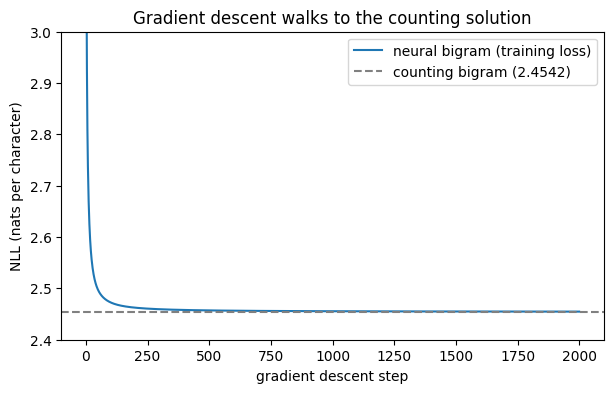

In [7]:
def train_neural_bigram(current_chars, next_chars, steps=2000, learning_rate=50.0, regularization=0.0):
    generator = torch.Generator().manual_seed(SEED)
    weights = torch.randn((vocab_size, vocab_size), generator=generator, requires_grad=True)
    losses = []
    for step in range(steps):
        logits = weights[current_chars]
        loss = F.cross_entropy(logits, next_chars) + regularization * (weights ** 2).mean()
        weights.grad = None
        loss.backward()
        with torch.no_grad():
            weights -= learning_rate * weights.grad
        losses.append(loss.item())
    return weights.detach(), losses


@torch.no_grad()
def bigram_weights_loss(weights, current_chars, next_chars):
    return F.cross_entropy(weights[current_chars], next_chars).item()


start = time.time()
neural_bigram_weights, neural_bigram_losses = train_neural_bigram(bigram_train_x, bigram_train_y)
print(f"2,000 full-batch steps in {time.time() - start:.0f}s; loss at step 0 was {neural_bigram_losses[0]:.3f}")

for split_name, (x, y) in bigram_splits.items():
    neural = bigram_weights_loss(neural_bigram_weights, x, y)
    counting = table_loss(counting_table, x, y)
    print(f"{split_name:5s}  neural {neural:.4f}   counting {counting:.4f}")


counting_train_loss = table_loss(counting_table, bigram_train_x, bigram_train_y)
plt.figure(figsize=(7, 4))
plt.plot(neural_bigram_losses, label="neural bigram (training loss)")
plt.axhline(counting_train_loss, color="gray", linestyle="--", label=f"counting bigram ({counting_train_loss:.4f})")
plt.ylim(2.4, 3.0)
plt.xlabel("gradient descent step")
plt.ylabel("NLL (nats per character)")
plt.title("Gradient descent walks to the counting solution")
plt.legend()
plt.savefig("neural_bigram_training.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
print("lambda    train     val")
for regularization in [0.0, 0.01, 0.1, 1.0, 10.0]:
    weights, _ = train_neural_bigram(bigram_train_x, bigram_train_y, steps=500, regularization=regularization)
    train_loss = bigram_weights_loss(weights, bigram_train_x, bigram_train_y)
    val_loss = bigram_weights_loss(weights, bigram_val_x, bigram_val_y)
    print(f"{regularization:<8} {train_loss:.4f}   {val_loss:.4f}")


lambda    train     val
0.0      2.4571   2.4551
0.01     2.4612   2.4594
0.1      2.5032   2.5020
1.0      2.7212   2.7217
10.0     3.1315   3.1318


In [9]:
learned_table = F.softmax(neural_bigram_weights, dim=1)
raw_counting_table = probability_table(bigram_counts, smoothing=0.0)
difference = (learned_table - raw_counting_table).abs()
print(f"largest probability difference {difference.max():.4f}, average {difference.mean():.5f}")



def sample_from_bigram(weights, how_many, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    samples = []
    for _ in range(how_many):
        current_index, letters = 0, []
        while True:
            probabilities = F.softmax(weights[current_index], dim=0)
            current_index = torch.multinomial(probabilities, num_samples=1, generator=generator).item()
            if current_index == 0:
                break
            letters.append(index_to_char[current_index])
        samples.append("".join(letters))
    return samples


print(sample_from_bigram(neural_bigram_weights, 10))

largest probability difference 0.0175, average 0.00036
['dexze', 'momakurailezitynn', 'konimittain', 'llayn', 'ka', 'da', 'staiyaubrtthrigotai', 'moliellavo', 'ke', 'teda']


In [10]:
def build_context_dataset(names, context_length):

    contexts, targets = [], []
    for name in names:
        context = [0] * context_length
        for char in name + ".":
            next_index = char_to_index[char]
            contexts.append(context)
            targets.append(next_index)
            context = context[1:] + [next_index]
    return torch.tensor(contexts), torch.tensor(targets)


emma_contexts, emma_targets = build_context_dataset(["emma"], context_length=3)
for context, target in zip(emma_contexts.tolist(), emma_targets.tolist()):
    print("".join(index_to_char[i] for i in context), "->", index_to_char[target])


train_contexts, train_targets = build_context_dataset(train_names, context_length=3)
print(train_contexts.shape, train_targets.shape)

... -> e
..e -> m
.em -> m
emm -> a
mma -> .
torch.Size([182625, 3]) torch.Size([182625])


In [11]:
class CharacterMLP(torch.nn.Module):


    def __init__(self, context_length, embedding_size, hidden_size, generator, careful_init=True):
        super().__init__()
        self.context_length = context_length
        input_size = context_length * embedding_size

        hidden_scale = (5 / 3) / input_size ** 0.5 if careful_init else 1.0
        small = 0.01 if careful_init else 1.0

        self.embedding_table = torch.nn.Parameter(torch.randn((vocab_size, embedding_size), generator=generator))
        self.hidden_weights = torch.nn.Parameter(torch.randn((input_size, hidden_size), generator=generator) * hidden_scale)
        self.hidden_bias = torch.nn.Parameter(torch.randn(hidden_size, generator=generator) * small)
        self.output_weights = torch.nn.Parameter(torch.randn((hidden_size, vocab_size), generator=generator) * small)
        self.output_bias = torch.nn.Parameter(torch.randn(vocab_size, generator=generator) * (0.0 if careful_init else 1.0))

    def hidden_activations(self, contexts):
        embedded = self.embedding_table[contexts]
        concatenated = embedded.view(len(contexts), -1)
        return torch.tanh(concatenated @ self.hidden_weights + self.hidden_bias)

    def forward(self, contexts):
        return self.hidden_activations(contexts) @ self.output_weights + self.output_bias


@torch.no_grad()
def mlp_loss(model, contexts, targets):
    return F.cross_entropy(model(contexts), targets).item()


def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters())


check_model = CharacterMLP(3, 10, 200, torch.Generator().manual_seed(SEED))
print("parameters:", count_parameters(check_model))
print("logits for 32 contexts:", check_model(train_contexts[:32]).shape)

parameters: 11897
logits for 32 contexts: torch.Size([32, 27])


plain N(0, 1) init  first loss  26.12   tanh units saturated 62%
careful init        first loss   3.31   tanh units saturated 10%


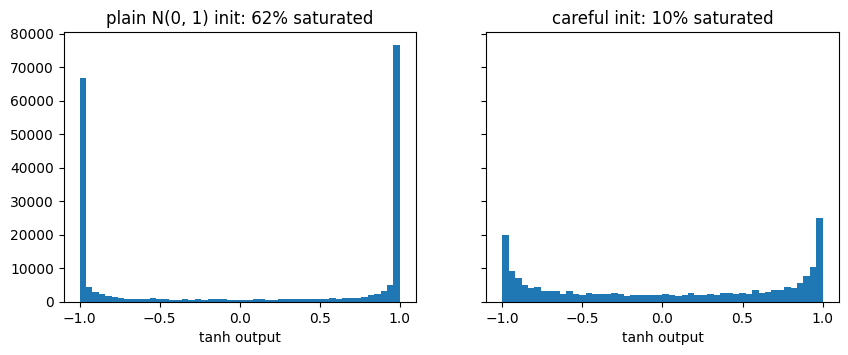

In [12]:
probe = torch.randint(0, len(train_contexts), (1000,), generator=torch.Generator().manual_seed(SEED))
probe_contexts, probe_targets = train_contexts[probe], train_targets[probe]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for axis, careful in zip(axes, [False, True]):
    model = CharacterMLP(3, 10, 200, torch.Generator().manual_seed(SEED), careful_init=careful)
    with torch.no_grad():
        first_loss = F.cross_entropy(model(probe_contexts), probe_targets).item()
        hidden = model.hidden_activations(probe_contexts)
    saturated = (hidden.abs() > 0.99).float().mean().item()
    label = "careful init" if careful else "plain N(0, 1) init"
    print(f"{label:19s} first loss {first_loss:6.2f}   tanh units saturated {saturated:.0%}")
    axis.hist(hidden.flatten().tolist(), bins=50)
    axis.set_title(f"{label}: {saturated:.0%} saturated")
    axis.set_xlabel("tanh output")
plt.savefig("init_histograms.png", dpi=150, bbox_inches="tight")
plt.show()


lowest smoothed loss 2.535 at learning rate 0.185


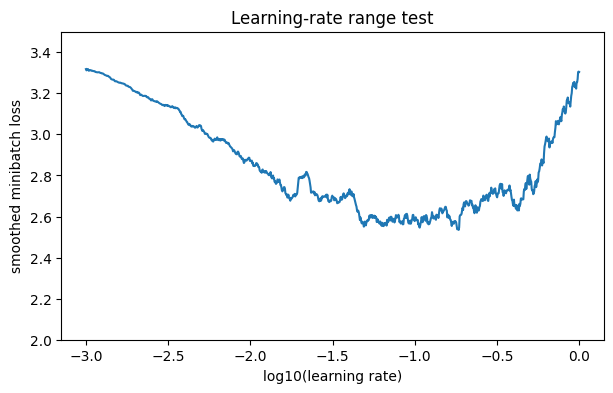

In [13]:
def learning_rate_range_test(steps=1000, batch_size=32):
    generator = torch.Generator().manual_seed(SEED)
    model = CharacterMLP(3, 10, 200, generator)
    learning_rates = 10 ** torch.linspace(-3, 0, steps)
    losses = []
    for step in range(steps):
        batch = torch.randint(0, len(train_contexts), (batch_size,), generator=generator)
        loss = F.cross_entropy(model(train_contexts[batch]), train_targets[batch])
        for parameter in model.parameters():
            parameter.grad = None
        loss.backward()
        with torch.no_grad():
            for parameter in model.parameters():
                parameter -= learning_rates[step] * parameter.grad
        losses.append(loss.item() if math.isfinite(loss.item()) else float("inf"))
    return learning_rates, losses


def moving_average(values, window=25):

    averaged = []
    for i in range(len(values)):
        chunk = values[max(0, i - window + 1): i + 1]
        averaged.append(sum(chunk) / len(chunk))
    return averaged


learning_rates, range_test_losses = learning_rate_range_test()
smoothed_losses = moving_average(range_test_losses)
best_step = min(range(len(smoothed_losses)), key=lambda i: smoothed_losses[i])
print(f"lowest smoothed loss {smoothed_losses[best_step]:.3f} at learning rate {learning_rates[best_step]:.3f}")


plt.figure(figsize=(7, 4))
plt.plot(torch.log10(learning_rates).tolist(), smoothed_losses)
plt.ylim(2.0, 3.5)
plt.xlabel("log10(learning rate)")
plt.ylabel("smoothed minibatch loss")
plt.title("Learning-rate range test")
plt.savefig("lr_range_test.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
def train_mlp(context_length=3, embedding_size=10, hidden_size=200, steps=200_000,
              batch_size=32, log_every=10_000):
    train_x, train_y = build_context_dataset(train_names, context_length)
    val_x, val_y = build_context_dataset(val_names, context_length)
    generator = torch.Generator().manual_seed(SEED)
    model = CharacterMLP(context_length, embedding_size, hidden_size, generator)

    history = []
    start = time.time()
    for step in range(steps + 1):
        if step % log_every == 0:
            history.append((step, mlp_loss(model, train_x, train_y), mlp_loss(model, val_x, val_y)))
            print(f"step {step:>7,}   train {history[-1][1]:.4f}   val {history[-1][2]:.4f}   ({time.time() - start:.0f}s)")
        if step == steps:
            break

        learning_rate = 0.1 if step < steps // 2 else 0.01
        batch = torch.randint(0, len(train_x), (batch_size,), generator=generator)
        loss = F.cross_entropy(model(train_x[batch]), train_y[batch])
        for parameter in model.parameters():
            parameter.grad = None
        loss.backward()
        with torch.no_grad():
            for parameter in model.parameters():
                parameter -= learning_rate * parameter.grad
    return model, history

step       0   train 3.3082   val 3.3080   (0s)
step  10,000   train 2.2444   val 2.2662   (5s)
step  20,000   train 2.1959   val 2.2253   (11s)
step  30,000   train 2.1869   val 2.2246   (15s)
step  40,000   train 2.1517   val 2.1931   (21s)
step  50,000   train 2.1515   val 2.1983   (25s)
step  60,000   train 2.1604   val 2.2085   (30s)
step  70,000   train 2.1506   val 2.2059   (35s)
step  80,000   train 2.1329   val 2.1836   (40s)
step  90,000   train 2.1393   val 2.1988   (45s)
step 100,000   train 2.1241   val 2.1774   (50s)
step 110,000   train 2.0504   val 2.1113   (55s)
step 120,000   train 2.0463   val 2.1077   (60s)
step 130,000   train 2.0452   val 2.1087   (65s)
step 140,000   train 2.0432   val 2.1078   (71s)
step 150,000   train 2.0424   val 2.1064   (75s)
step 160,000   train 2.0411   val 2.1073   (81s)
step 170,000   train 2.0399   val 2.1054   (85s)
step 180,000   train 2.0396   val 2.1053   (90s)
step 190,000   train 2.0389   val 2.1053   (95s)
step 200,000   train 2

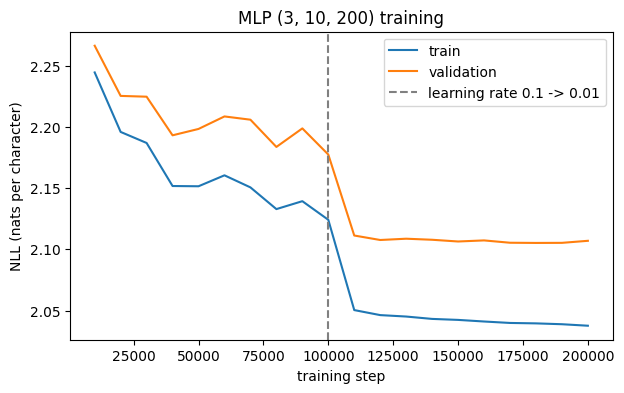

In [15]:
main_model, main_history = train_mlp(context_length=3, embedding_size=10, hidden_size=200)


steps_logged = [step for step, _, _ in main_history]
plt.figure(figsize=(7, 4))
plt.plot(steps_logged[1:], [train for _, train, _ in main_history][1:], label="train")
plt.plot(steps_logged[1:], [val for _, _, val in main_history][1:], label="validation")
plt.axvline(100_000, color="gray", linestyle="--", label="learning rate 0.1 -> 0.01")
plt.xlabel("training step")
plt.ylabel("NLL (nats per character)")
plt.title("MLP (3, 10, 200) training")
plt.legend()
plt.savefig("mlp_training_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
size_experiments = [

    (3, 2, 200, 200_000),
    (3, 16, 300, 200_000),
    (4, 16, 300, 300_000),
]

trained_models = {(3, 10, 200): main_model}
final_losses = {(3, 10, 200): main_history[-1][1:]}

for context_length, embedding_size, hidden_size, steps in size_experiments:
    config = (context_length, embedding_size, hidden_size)
    print(f"\ncontext {context_length}, embedding {embedding_size}, hidden {hidden_size}")
    model, history = train_mlp(context_length, embedding_size, hidden_size, steps, log_every=50_000)
    trained_models[config] = model
    final_losses[config] = history[-1][1:]

print("\ncontext  embed  hidden   params    train     val      gap")
for config, (train_loss, val_loss) in sorted(final_losses.items(), key=lambda item: item[1][1], reverse=True):
    params = count_parameters(trained_models[config])
    print(f"{config[0]:>7} {config[1]:>6} {config[2]:>7} {params:>8,}   {train_loss:.3f}   {val_loss:.3f}   {val_loss - train_loss:.3f}")



context 3, embedding 2, hidden 200
step       0   train 3.3000   val 3.3006   (0s)
step  50,000   train 2.2744   val 2.2953   (23s)
step 100,000   train 2.2533   val 2.2764   (45s)
step 150,000   train 2.1586   val 2.1860   (66s)
step 200,000   train 2.1542   val 2.1792   (90s)

context 3, embedding 16, hidden 300
step       0   train 3.3143   val 3.3155   (1s)
step  50,000   train 2.1639   val 2.2198   (27s)
step 100,000   train 2.1197   val 2.1911   (54s)
step 150,000   train 2.0017   val 2.0872   (80s)
step 200,000   train 1.9948   val 2.0886   (107s)

context 4, embedding 16, hidden 300
step       0   train 3.2947   val 3.2944   (1s)
step  50,000   train 2.0646   val 2.1606   (28s)
step 100,000   train 2.0104   val 2.1538   (56s)
step 150,000   train 1.9905   val 2.1585   (84s)
step 200,000   train 1.8551   val 2.0418   (111s)
step 250,000   train 1.8483   val 2.0447   (139s)
step 300,000   train 1.8427   val 2.0494   (166s)

context  embed  hidden   params    train     val      g

| Model | Test NLL |
| --- | --- |
| Uniform guessing | 3.296 |
| Bigram, counting | 2.458 |
| Bigram, neural | 2.458 |
| Trigram, counting | 2.224 |
| MLP (3, 10, 200), 11,897 params | 2.105 |
| MLP (4, 16, 300), 28,059 params | 2.041 |


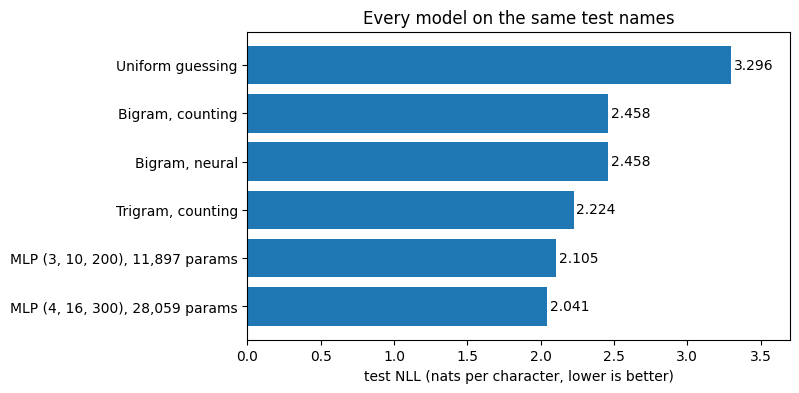

In [17]:
def trigram_test_loss(smoothing=0.1):

    train_x, train_y = build_context_dataset(train_names, context_length=2)
    test_x, test_y = build_context_dataset(test_names, context_length=2)
    counts = torch.zeros((vocab_size, vocab_size, vocab_size))
    counts.index_put_((train_x[:, 0], train_x[:, 1], train_y), torch.ones(len(train_y)), accumulate=True)
    table = (counts + smoothing) / (counts + smoothing).sum(dim=2, keepdim=True)
    return -table[test_x[:, 0], test_x[:, 1], test_y].log().double().mean().item()


def mlp_test_loss(config):
    test_x, test_y = build_context_dataset(test_names, context_length=config[0])
    return mlp_loss(trained_models[config], test_x, test_y)


best_config = min(final_losses, key=lambda config: final_losses[config][1])
results = {
    "Uniform guessing": math.log(vocab_size),
    "Bigram, counting": table_loss(counting_table, bigram_test_x, bigram_test_y),
    "Bigram, neural": bigram_weights_loss(neural_bigram_weights, bigram_test_x, bigram_test_y),
    "Trigram, counting": trigram_test_loss(),
    f"MLP {(3, 10, 200)}, {count_parameters(main_model):,} params": mlp_test_loss((3, 10, 200)),
    f"MLP {best_config}, {count_parameters(trained_models[best_config]):,} params": mlp_test_loss(best_config),
}

print("| Model | Test NLL |\n| --- | --- |")
for model_name, loss in results.items():
    print(f"| {model_name} | {loss:.3f} |")


plt.figure(figsize=(7, 4))
plt.barh(list(results.keys())[::-1], list(results.values())[::-1])
for row, loss in enumerate(list(results.values())[::-1]):
    plt.text(loss + 0.02, row, f"{loss:.3f}", va="center")
plt.xlim(0, 3.7)
plt.xlabel("test NLL (nats per character, lower is better)")
plt.title("Every model on the same test names")
plt.savefig("results.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
@torch.no_grad()
def sample_from_mlp(model, how_many, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    samples = []
    for _ in range(how_many):
        context = [0] * model.context_length
        letters = []
        while True:
            probabilities = F.softmax(model(torch.tensor([context])), dim=1)
            next_index = torch.multinomial(probabilities, num_samples=1, generator=generator).item()
            if next_index == 0:
                break
            letters.append(index_to_char[next_index])
            context = context[1:] + [next_index]
        samples.append("".join(letters))
    return samples


for name in sample_from_mlp(trained_models[best_config], 15):
    print(name)

cexi
kaegan
raileigha
kell
imitra
nolliver
andr
samiyah
jaxsiyi
taimie
jenan
kinzleeda
kaleyda
sade
eniavi


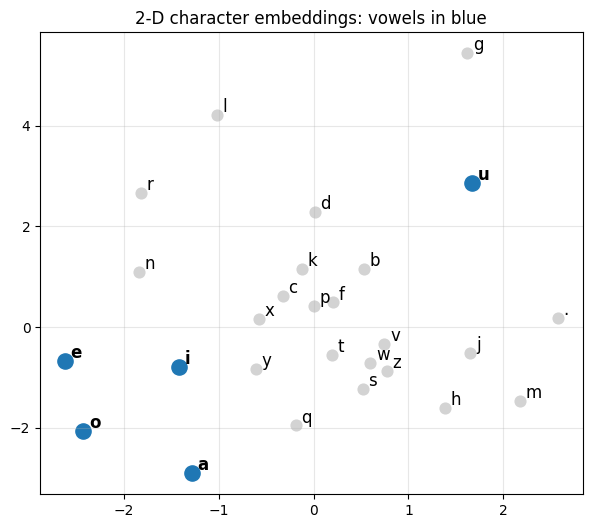

In [19]:
embedding_2d = trained_models[(3, 2, 200)].embedding_table.detach()
vowels = set("aeiou")

plt.figure(figsize=(7, 6))
for index, char in index_to_char.items():
    x, y = embedding_2d[index].tolist()
    is_vowel = char in vowels
    plt.scatter(x, y, s=120 if is_vowel else 60, color="tab:blue" if is_vowel else "lightgray")
    plt.text(x + 0.06, y + 0.06, char, fontsize=12, fontweight="bold" if is_vowel else "normal")
plt.title("2-D character embeddings: vowels in blue")
plt.grid(alpha=0.3)
plt.savefig("embeddings_2d.png", dpi=150, bbox_inches="tight")
plt.show()
